<a href="https://colab.research.google.com/github/rj3005006-ui/AI-pioneers-internship/blob/main/TASK1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [16]:
# Save the processed dataset
processed_df.to_csv("preprocessed_iris.csv", index=False)

# Download the CSV to your PC
from google.colab import files
files.download("preprocessed_iris.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import LabelEncoder, MinMaxScaler

In [4]:
# Load the Iris dataset
iris = load_iris(as_frame=True)
df = iris.frame

# Display the dataset
print("First five rows:")
print(df.head())

First five rows:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target  
0       0  
1       0  
2       0  
3       0  
4       0  


In [6]:
# Explore the dataset
print("\nDataset shape:", df.shape)
print("\nDataset information:")
df.info()
print("\nStatistical summary:")
print(df.describe())


Dataset shape: (150, 5)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB

Statistical summary:
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000         

In [7]:

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Handle missing numerical values
df = df.fillna(df.median(numeric_only=True))



Missing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64


In [8]:
# Remove duplicate records
df = df.drop_duplicates()

# Separate features and target
X = df.drop(columns=["target"])
y = df["target"]

In [9]:
# Encode the target labels
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)

# Normalize numerical features
scaler = MinMaxScaler()
X_scaled = pd.DataFrame(
    scaler.fit_transform(X),
    columns=X.columns
)


In [10]:
# Display the processed data
print("\nNormalized features:")
print(X_scaled.head())

print("\nEncoded target labels:")
print(y_encoded[:5])

print("\nMissing values after preprocessing:")
print(X_scaled.isnull().sum())


Normalized features:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0           0.222222          0.625000           0.067797          0.041667
1           0.166667          0.416667           0.067797          0.041667
2           0.111111          0.500000           0.050847          0.041667
3           0.083333          0.458333           0.084746          0.041667
4           0.194444          0.666667           0.067797          0.041667

Encoded target labels:
[0 0 0 0 0]

Missing values after preprocessing:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64


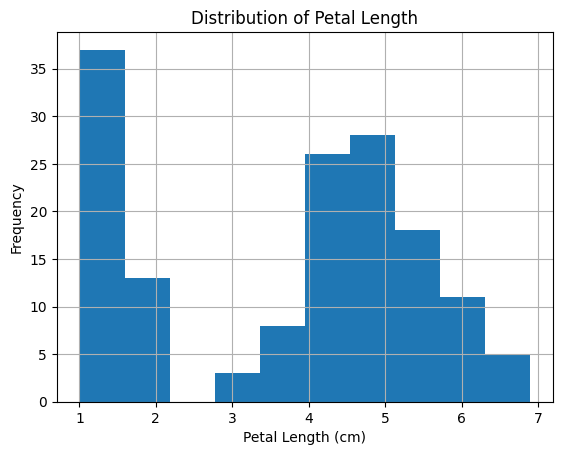


Preprocessed dataset saved successfully.


In [11]:
# Visualize a feature distribution
X["petal length (cm)"].hist()
plt.title("Distribution of Petal Length")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Frequency")
plt.show()

# Save the preprocessed dataset
processed_df = X_scaled.copy()
processed_df["target"] = y_encoded
processed_df.to_csv("preprocessed_iris.csv", index=False)

print("\nPreprocessed dataset saved successfully.")